# Thiết kế bộ lọc IIR (Infinite Impulse Response)

Thiết kế bộ lọc IIR (Infinite Impulse Response) loại Butterworth là một lựa chọn phổ biến trong xử lý tín hiệu số vì đặc tính **"phẳng tối đa" (maximally flat)** trong dải thông, nghĩa là nó không có gợn sóng (ripple) làm méo tín hiệu ở những tần số chúng ta muốn giữ lại.

Dưới đây là hướng dẫn chi tiết và mã nguồn Python để thiết kế bộ lọc này.

### Các bước cơ bản để thiết kế

Để thiết kế bộ lọc, bạn cần xác định các thông số chính sau:

1. **Thứ tự bộ lọc (Order):** Bậc càng cao, độ dốc cắt càng lớn (lọc càng sạch) nhưng tính toán chậm hơn và có thể gây trễ pha (phase delay).
2. **Tần số lấy mẫu ():** Tần số thu thập dữ liệu của tín hiệu (Hz).
3. **Tần số cắt ():** Tần số mà tại đó bộ lọc bắt đầu làm suy giảm tín hiệu (thường là điểm -3dB).
4. **Loại bộ lọc:** Thấp qua (lowpass), cao qua (highpass), dải qua (bandpass), hoặc dải chặn (bandstop).

---

### Mã nguồn Python (Sử dụng `scipy` và `numpy`)

Chúng ta sẽ sử dụng thư viện `scipy.signal`, đây là công cụ tiêu chuẩn công nghiệp cho việc này.


### Giải thích các hàm quan trọng

Được rồi, tôi sẽ chuyển sang sử dụng định dạng đầu ra "truyền thống" là **`b, a`** (tử số và mẫu số của hàm truyền).

Trong `scipy`, định dạng này được gọi là `output='ba'`. Khi dùng định dạng này, chúng ta sẽ không dùng `sosfilt` nữa mà sẽ dùng hàm **`lfilter`** (linear filter).

Đây là cấu trúc của một bộ lọc IIR Direct Form II mà các hệ số `b` và `a` sẽ đại diện:

Dưới đây là mã nguồn Python chi tiết:

### Mã nguồn Python (Sử dụng `b, a` và `lfilter`)


### Điểm khác biệt chính cần lưu ý

1. **Hàm `signal.lfilter(b, a, data)`:**
* Đây là hàm chuẩn để chạy bộ lọc khi bạn có `b` và `a`.
* Về mặt toán học, nó giải phương trình sai phân (Difference Equation):
$$
y[n] = \sum_{i=0}^{M} b_i x[n-i] - \sum_{j=1}^{N} a_j y[n-j]
$$


(Lưu ý: trong Python `scipy`, thường ).


2. **Cảnh báo về sự ổn định (Stability Warning):**
* **Tại sao người ta ít dùng `ba` cho bậc cao?** Khi bạn tăng bậc bộ lọc (ví dụ `order > 10`) hoặc khi tần số cắt quá thấp so với tần số lấy mẫu, các hệ số `a` và `b` sẽ chênh lệch nhau rất lớn (một số rất to, một số rất nhỏ).
* Điều này dẫn đến **sai số làm tròn (numerical precision errors)** khiến bộ lọc bị nổ (không ổn định) hoặc lọc sai.
* **Lời khuyên:** Nếu dùng dạng `ba`, hãy cố gắng giữ bậc bộ lọc thấp (thường là dưới 6 hoặc 8).


Hệ số b (Tử số): [9.58212909e-14 1.72478324e-12 1.46606575e-11 7.81901734e-11
 2.93213150e-10 8.20996820e-10 1.77882644e-09 3.04941676e-09
 4.19294805e-09 4.65883116e-09 4.19294805e-09 3.04941676e-09
 1.77882644e-09 8.20996820e-10 2.93213150e-10 7.81901734e-11
 1.46606575e-11 1.72478324e-12 9.58212909e-14]
Hệ số a (Mẫu số): [ 1.00000000e+00 -1.30965543e+01  8.15139923e+01 -3.20263686e+02
  8.89817890e+02 -1.85602886e+03  3.01130767e+03 -3.88479819e+03
  4.03887703e+03 -3.40864551e+03  2.34036559e+03 -1.30395662e+03
  5.85082501e+02 -2.08523039e+02  5.77241916e+01 -1.19747346e+01
  1.75279828e+00 -1.61530417e-01  7.05266881e-03]
[0.00000000e+00 3.92699082e-04 7.85398163e-04 ... 3.14041456e+00
 3.14080726e+00 3.14119995e+00]
[0.00000000e+00 2.75625000e+00 5.51250000e+00 ... 2.20417313e+04
 2.20444875e+04 2.20472438e+04]


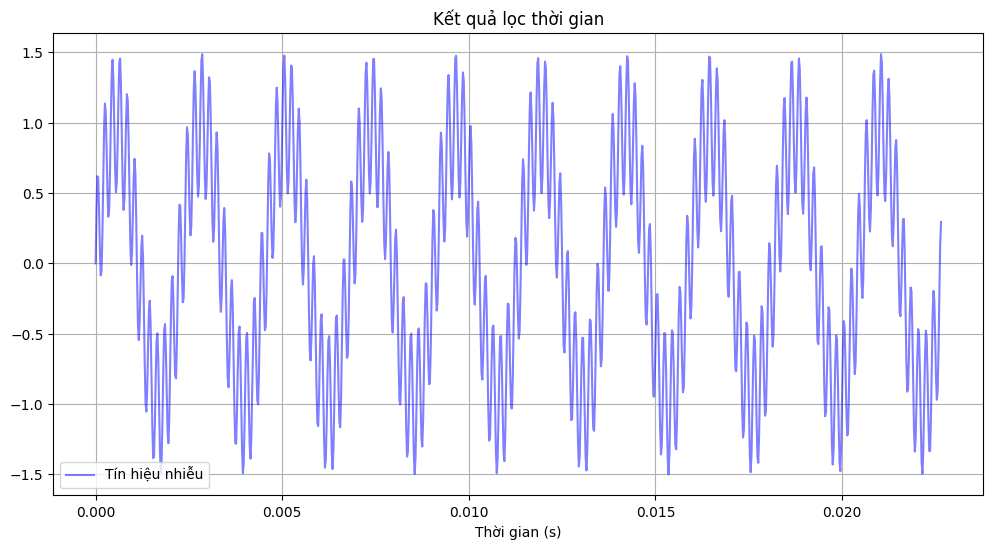

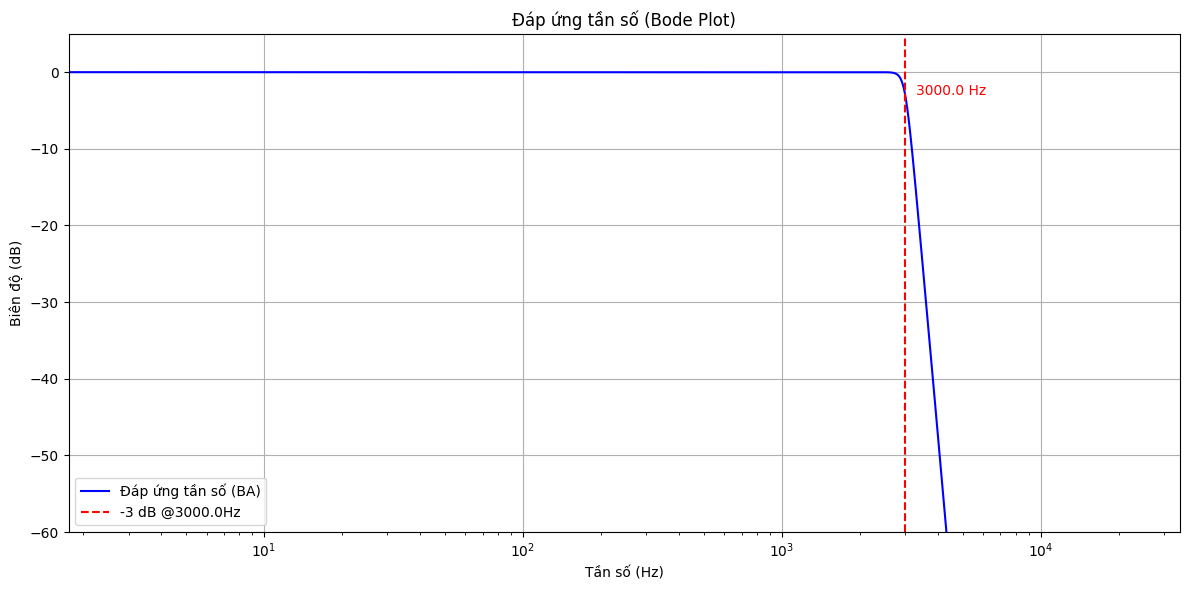

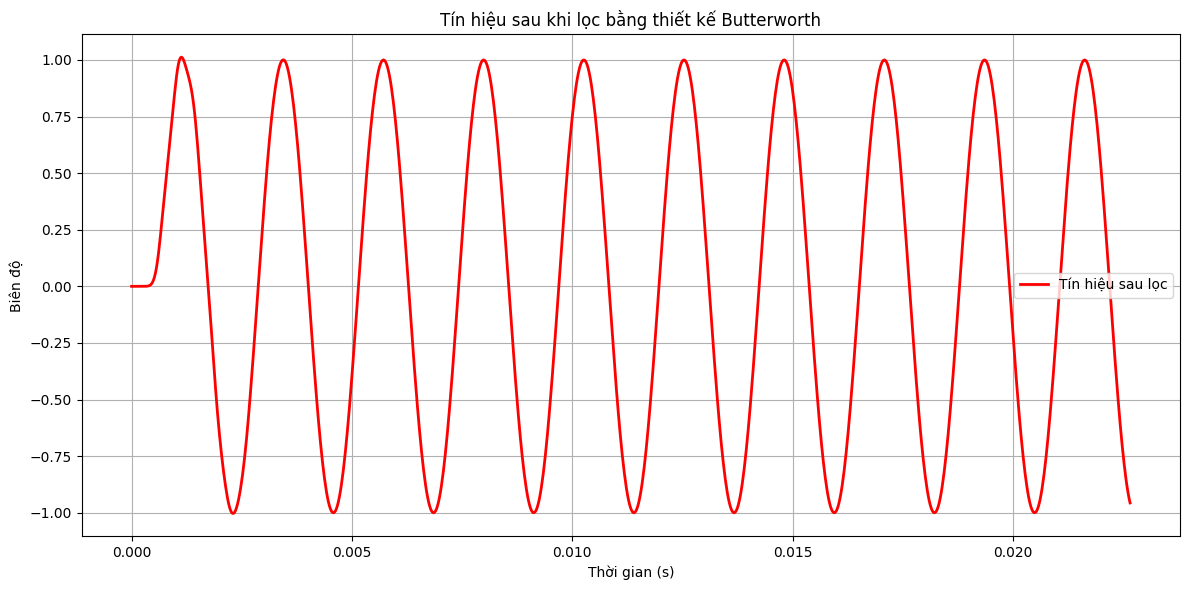

In [1]:
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt
from control import bode_plot

def thiet_ke_va_loc_butterworth_ba(cutoff, fs, order=4, btype='low'):
    """
    Thiết kế bộ lọc Butterworth trả về hệ số b, a.
    
    Tham số:
    - data: Dữ liệu đầu vào.
    - cutoff: Tần số cắt (Hz).
    - fs: Tần số lấy mẫu (Hz).
    - order: Bậc bộ lọc.
    - btype: Loại ('low', 'high', 'band').
    
    Trả về:
    - y: Tín hiệu đã lọc.
    - b, a: Các hệ số của bộ lọc.
    """
    # 1. Tính tần số Nyquist
    nyquist = 0.5 * fs
    
    # 2. Chuẩn hóa tần số cắt
    if isinstance(cutoff, list):
        normal_cutoff = [x / nyquist for x in cutoff]
    else:
        normal_cutoff = cutoff / nyquist

    # 3. Tính toán hệ số b (tử số) và a (mẫu số)
    # output='ba' là dạng truyền thống
    b, a = signal.butter(order, normal_cutoff, btype=btype, analog=False, output='ba')

    # 4. Lọc dữ liệu bằng lfilter (Linear Filter)
    # Đây là hàm thực hiện phương trình sai phân: a[0]*y[n] = b[0]*x[n] + b[1]*x[n-1] + ... - a[1]*y[n-1] - ...
    
    return b, a

# --- VÍ DỤ MINH HỌA ---

# Tạo dữ liệu giả lập
fs = 44100  # Tần số lấy mẫu
t = np.arange(0, 1.0, 1/fs)
# Tín hiệu sạch fL Hz + Nhiễu tần số cao fH Hz
fL = 440 # Tần số thấp (Hz)
fH = 5000 # Tần số cao (Hz)
noisy_signal = np.sin(2 * np.pi * fL * t) + 0.5 * np.sin(2 * np.pi * fH * t)

# Thiết lập bộ lọc Lowpass Hz, bậc 4
cutoff_freq = 3000.0
filter_order = 18

# Thiết kế bộ lọc Butterworth và lấy hệ số b, a
b, a = thiet_ke_va_loc_butterworth_ba(cutoff_freq, fs, order=filter_order, btype='low')


# Thực hiện lọc
filtered_signal = signal.lfilter(b, a, noisy_signal)

# In thử hệ số b và a để kiểm tra
print("Hệ số b (Tử số):", b)
print("Hệ số a (Mẫu số):", a)

# --- VẼ ĐỒ THỊ ---
plt.figure(figsize=(12, 6))

sample_to_crop = 1000
t_cropped = t[:sample_to_crop]  # Chỉ vẽ phần đầu để thấy rõ hiệu quả lọc

# Vẽ tín hiệu
plt.plot(t_cropped, noisy_signal[:sample_to_crop], 'b-', label='Tín hiệu nhiễu', alpha=0.5)
plt.title('Kết quả lọc thời gian')
plt.xlabel('Thời gian (s)')
plt.legend()
plt.grid(True)

# Vẽ đáp ứng tần số (Freq Response) dùng b, a
plt.figure(figsize=(12, 6))
# Dùng freqz cho dạng ba
w, h = signal.freqz(b, a, worN=8000)
print(w)
freq_hz = (fs * 0.5 / np.pi) * w # Chuyển đổi trục x sang Hz
print(freq_hz)
# plot giong bode plot, tan so duoc chia khoan theo logarit, do thi duoc chia khoan theo logarit, va do thi duoc chia khoan theo logarit
plt.semilogx(freq_hz, 20 * np.log10(np.abs(h)), 'b-', label='Đáp ứng tần số (BA)')

plt.axvline(cutoff_freq, color='r', linestyle='--', label= f'-3 dB @{cutoff_freq}Hz')
plt.text(cutoff_freq*1.1, -3, f'{cutoff_freq} Hz', color='r')
plt.title('Đáp ứng tần số (Bode Plot)')
plt.xlabel('Tần số (Hz)')
plt.ylabel('Biên độ (dB)')
plt.ylim(-60, 5)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

# Tin hieu sau khi loc nhieu bang thiet ke_va_loc_butterworth_ba
plt.figure(figsize=(12, 6))
plt.plot(t_cropped, filtered_signal[:sample_to_crop], 'r-', label='Tín hiệu sau lọc', linewidth=2)
plt.title('Tín hiệu sau khi lọc bằng thiết kế Butterworth')
plt.xlabel('Thời gian (s)')
plt.ylabel('Biên độ')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Xem đáp ứng tần số với các bậc khác nhau

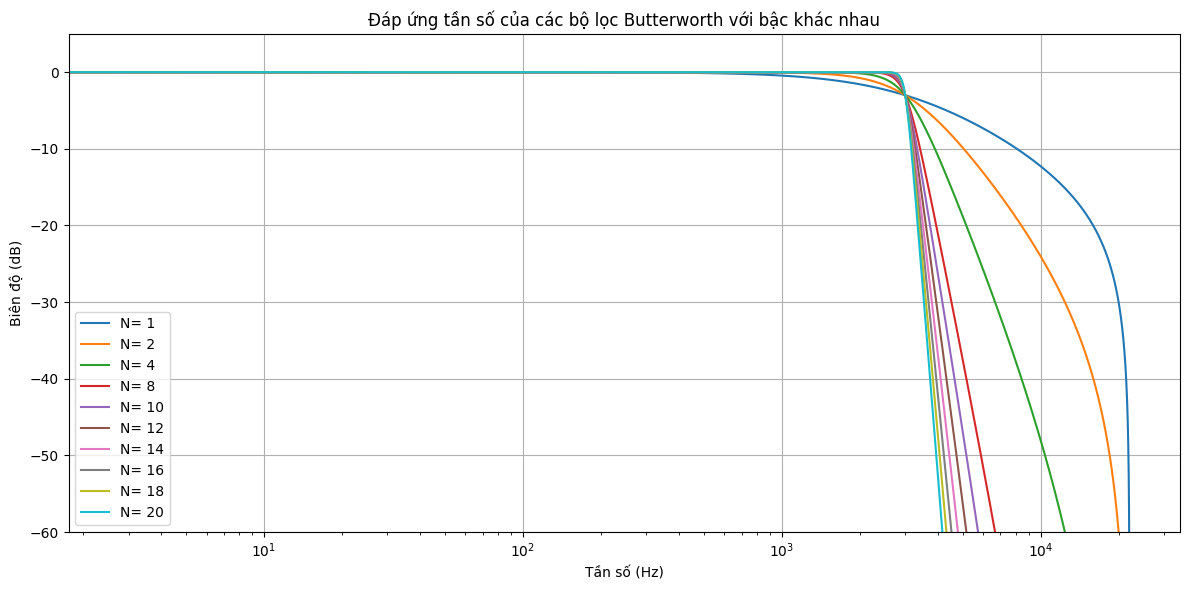

In [2]:
# listing the bode with various orders
order_list = [1, 2, 4, 8, 10, 12, 14, 16, 18, 20]
plt.figure(figsize=(12, 6))
for order in order_list:
    b, a = signal.butter(order, cutoff_freq / (0.5 * fs), btype='low', output='ba')
    w, h = signal.freqz(b, a, worN=8000)
    freq_hz = (fs * 0.5 / np.pi) * w
    plt.semilogx(freq_hz, 20 * np.log10(np.abs(h)), label=f'N= {order}')
plt.title('Đáp ứng tần số của các bộ lọc Butterworth với bậc khác nhau')
plt.xlabel('Tần số (Hz)')
plt.ylabel('Biên độ (dB)')
plt.ylim(-60, 5)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.grid(True)
plt.show()


## Nhiệm vụ của bạn: 
